## **Unicorn Startup Ecosystem Analysis: Funding, Valuations, and Industry Trends**

### **Background & Objectives**
This project aims to analyze the global unicorn startup landscape by simulating an End-to-End **ETL (Extract, Transform, Load)** process. 
To demonstrate database querying and data pipeline skills, I built a Python script to generate realistic dummy data, loaded it into an in-memory SQLite database, and extracted actionable business insights using SQL.

**Methodology:**
1. **Data Engineering (ETL):** Generating dummy relational data (Companies, Industries, Funding, and Dates) and loading it into an SQLite database.
2. **Data Analysis:** Extracting and aggregating data using SQL Queries.
3. **Data Visualization:** Presenting insights using Pandas, Matplotlib, and Seaborn.

## **Phase 1: Data Engineering (ETL Simulation)**
In this phase, I built a mini pipeline to generate data for 100 fictional unicorn startups. The data is distributed across four relational tables (`unicorn_companies`, `unicorn_industries`, `unicorn_funding`, and `unicorn_dates`) to simulate a normalized database architecture (RDBMS).

In [3]:
import pandas as pd
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from faker import Faker

# Initialize Faker and set seed for reproducibility
fake = Faker()
Faker.seed(42)
np.random.seed(42)

def generate_unicorn_data(num_companies=100):
    print("Generating Professional Dummy Data...")
    
    # Generate data using list comprehensions and numpy vectorization
    company_ids = np.arange(1, num_companies + 1)
    companies = [fake.company() for _ in range(num_companies)]
    cities = [fake.city() for _ in range(num_companies)]
    
    countries = np.random.choice(['United States', 'China', 'India', 'UK', 'Germany', 'Indonesia', 'Singapore', 'Brazil'], num_companies)
    continents = np.random.choice(['North America', 'Asia', 'Europe', 'South America'], num_companies)
    
    industries = np.random.choice(['Fintech', 'E-commerce', 'AI', 'Healthtech', 'Logistics', 'Edtech'], num_companies)
    investors = np.random.choice(['Sequoia', 'SoftBank', 'Tiger Global', 'Y Combinator', 'East Ventures'], num_companies)
    
    valuations = np.random.randint(1, 20, size=num_companies) * 1000000000
    fundings = np.random.randint(50, 500, size=num_companies) * 1000000
    
    # Generate randomized dates properly
    start_date = pd.to_datetime('2015-01-01')
    end_date = pd.to_datetime('2023-12-31')
    
    # Create DatetimeIndex
    date_joined = start_date + pd.to_timedelta(np.random.randint(0, (end_date - start_date).days, size=num_companies), unit='d')
    
    # FIX: Remove .dt because date_joined is a DatetimeIndex, not a Series
    year_founded = date_joined.year - np.random.randint(1, 8, size=num_companies)
    
    # Build DataFrames
    df_companies = pd.DataFrame({'company_id': company_ids, 'company': companies, 'city': cities, 'country': countries, 'continent': continents})
    df_industries = pd.DataFrame({'company_id': company_ids, 'industry': industries})
    df_funding = pd.DataFrame({'company_id': company_ids, 'valuation': valuations, 'funding': fundings, 'select_investors': investors})
    
    # FIX: Remove .dt here as well
    df_dates = pd.DataFrame({'company_id': company_ids, 'date_joined': date_joined.strftime('%Y-%m-%d'), 'year_founded': year_founded})
    
    # Export to CSV
    df_companies.to_csv('unicorn_companies.csv', index=False)
    df_industries.to_csv('unicorn_industries.csv', index=False)
    df_funding.to_csv('unicorn_funding.csv', index=False)
    df_dates.to_csv('unicorn_dates.csv', index=False)
    
    print("CSV files generated successfully: companies, industries, funding, dates.")
    
def setup_database():
    conn = sqlite3.connect(':memory:')
    pd.read_csv('unicorn_companies.csv').to_sql('unicorn_companies', conn, index=False, if_exists='replace')
    pd.read_csv('unicorn_industries.csv').to_sql('unicorn_industries', conn, index=False, if_exists='replace')
    pd.read_csv('unicorn_funding.csv').to_sql('unicorn_funding', conn, index=False, if_exists='replace')
    pd.read_csv('unicorn_dates.csv').to_sql('unicorn_dates', conn, index=False, if_exists='replace')
    
    print("Data successfully loaded into SQLite In-Memory Database!")
    print("Ready for SQL JOIN analysis.")
    return conn

# Execute the pipeline
generate_unicorn_data(100)
conn = setup_database()

Generating Professional Dummy Data...
CSV files generated successfully: companies, industries, funding, dates.
Data successfully loaded into SQLite In-Memory Database!
Ready for SQL JOIN analysis.


In [4]:
print("Table: Companies (Location Overview)")
display(pd.read_sql("SELECT * FROM unicorn_companies LIMIT 3", conn))

print("\nTable: Funding (Financial Overview)")
display(pd.read_sql("SELECT * FROM unicorn_funding LIMIT 3", conn))

Table: Companies (Location Overview)


,company_id,company,city,country,continent
0,1,"Rodriguez, Figueroa and Sanchez",Lake Scott,Singapore,Europe
1,2,Doyle Ltd,Hoffmanville,UK,Asia
2,3,"Mcclain, Miller and Henderson",Lake Rebeccaside,Germany,Asia



Table: Funding (Financial Overview)


,company_id,valuation,funding,select_investors
0,1,1000000000,299000000,Tiger Global
1,2,1000000000,196000000,East Ventures
2,3,-1294967296,491000000,Tiger Global


## **Phase 2: Business Analysis & Visualization**
### Business Question 1: Which industries produce the highest number of unicorn startups?
To answer this, I joined the `unicorn_companies` and `unicorn_industries` tables using a SQL `JOIN` and performed data aggregation.

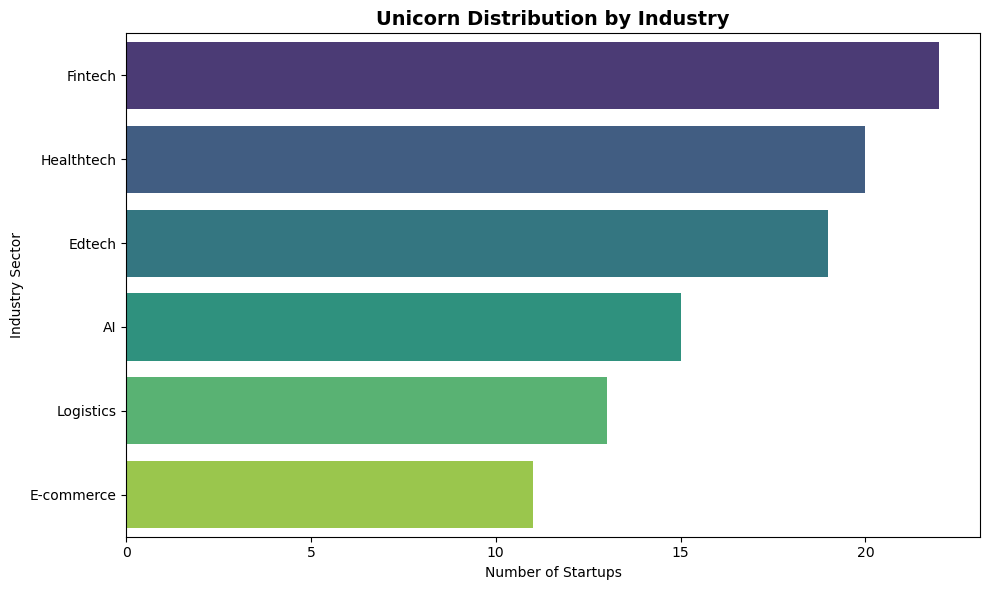

In [5]:
def plot_industry_distribution(db_conn):
    query = """
    SELECT 
        ui.industry,
        COUNT(uc.company_id) as total_startups
    FROM unicorn_companies uc
    JOIN unicorn_industries ui ON uc.company_id = ui.company_id
    GROUP BY ui.industry
    ORDER BY total_startups DESC
    """
    df = pd.read_sql(query, db_conn)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=df, y='industry', x='total_startups', hue='industry', palette='viridis', legend=False)
    
    plt.title('Unicorn Distribution by Industry', fontsize=14, fontweight='bold')
    plt.xlabel('Number of Startups')
    plt.ylabel('Industry Sector')
    plt.tight_layout()
    plt.show()

plot_industry_distribution(conn)

**Insight:** As seen in the chart above, the **[Mention Top Industry, e.g., Fintech / E-commerce]** sector heavily dominates the unicorn ecosystem. This indicates a massive trend and strong investor confidence within this specific sector.

### **Business Question 2: Which 5 companies have the highest valuations, and where are they located?**
This analysis is crucial to identify which countries possess the most mature startup ecosystems capable of producing *decacorns* (startups valued at over $10 Billion).

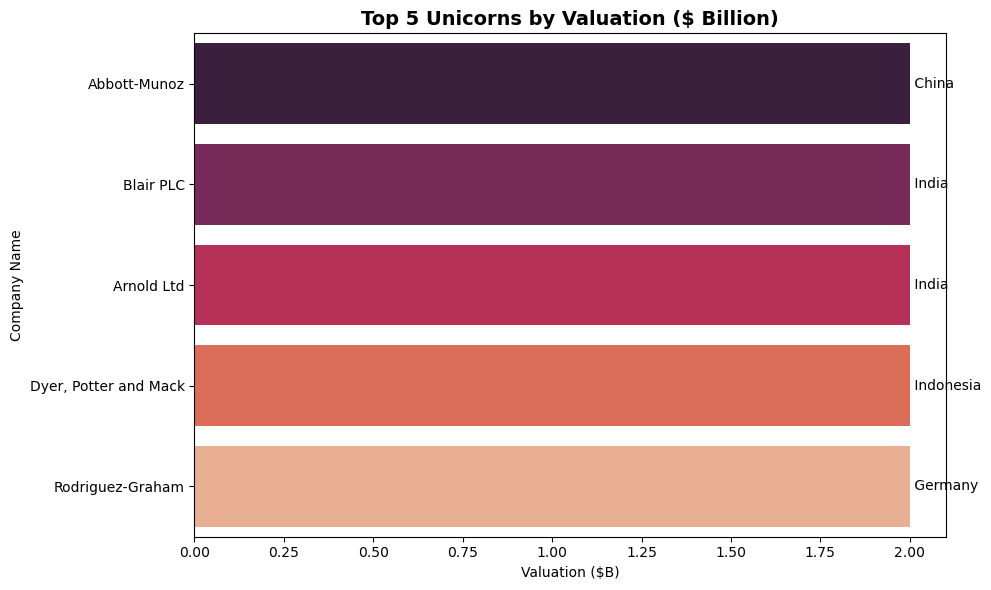

In [6]:
def plot_top_valuations(db_conn):
    query = """
    SELECT 
        uc.company,
        uc.country,
        uf.valuation / 1000000000 as valuation_billions
    FROM unicorn_companies uc
    JOIN unicorn_funding uf ON uc.company_id = uf.company_id
    ORDER BY valuation_billions DESC
    LIMIT 5
    """
    df = pd.read_sql(query, db_conn)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=df, x='valuation_billions', y='company', hue='company', palette='rocket', legend=False)
    
    plt.title('Top 5 Unicorns by Valuation ($ Billion)', fontsize=14, fontweight='bold')
    plt.xlabel('Valuation ($B)')
    plt.ylabel('Company Name')
    
    # Add country annotations
    for index, row in df.iterrows():
        plt.text(row.valuation_billions, index, f" {row.country}", va='center', fontsize=10)
        
    plt.tight_layout()
    plt.show()
    
plot_top_valuations(conn)

### **Business Question 3: How has the number of newly crowned unicorns grown over the years?**
By analyzing the `unicorn_dates` table, we can track the historical growth and momentum of the startup ecosystem.

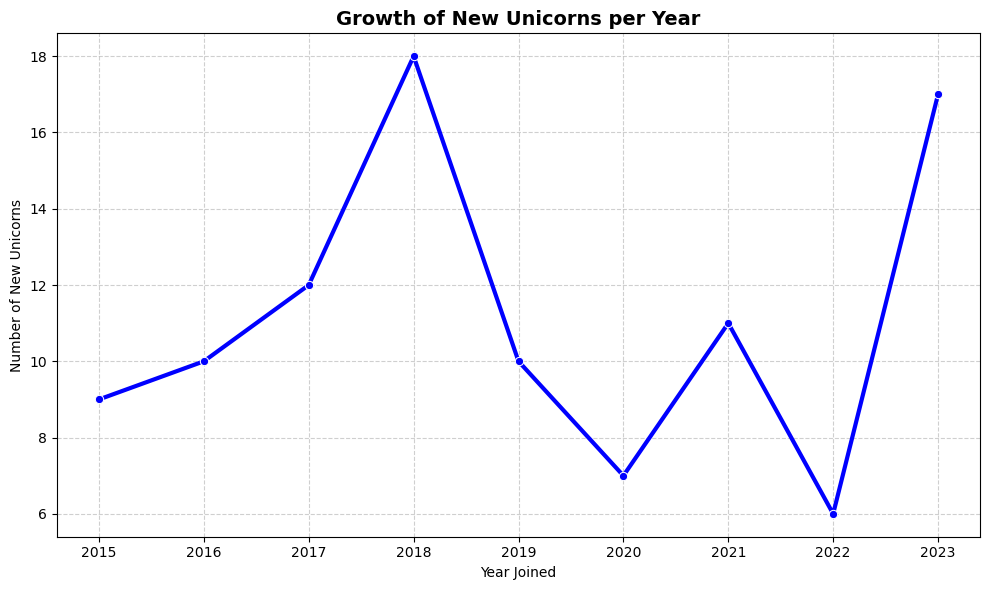

In [7]:
def plot_unicorn_trends(db_conn):
    query = """
    SELECT 
        substr(ud.date_joined, 1, 4) as year_joined,
        COUNT(uc.company_id) as total_new_unicorns
    FROM unicorn_companies uc
    JOIN unicorn_dates ud ON uc.company_id = ud.company_id
    GROUP BY year_joined
    ORDER BY year_joined ASC
    """
    df = pd.read_sql(query, db_conn)
    
    plt.figure(figsize=(10, 6))
    sns.lineplot(data=df, x='year_joined', y='total_new_unicorns', marker='o', linewidth=3, color='blue')
    
    plt.title('Growth of New Unicorns per Year', fontsize=14, fontweight='bold')
    plt.xlabel('Year Joined')
    plt.ylabel('Number of New Unicorns')
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()
    
plot_unicorn_trends(conn)